# 14 — LPPLS + XGBoost: wykrywanie stanów anomalii spekulacyjnej
Cel: klasyfikować w dniu t stan wg referencji BSADF z notatnika 13.
To **naśladowanie niezależnego testu referencyjnego / nowcasting**, a nie
bezpośrednie wykrywanie fundamentalnej bańki ani przewidywanie jej końca.

Proponowany model: XGBoost (Price+LPPLS). Benchmarki: XGB Price-only,
XGB LPPLS-only, regresja logistyczna, prosta reguła Confidence Indicator.

Outer: rozszerzający się trening do roku t-2, walidacja t-1, test t.
Inner: min. dwa podziały chronologiczne tylko w treningu do doboru HP.
Próg dobierany tylko na walidacji t-1; test nie wpływa na wybór.
Wszystkie modele są trenowane na tych samych datach.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import ParameterSampler
from xgboost import XGBClassifier
import joblib
from bubble_tools import load_prices, build_daily_features, classification_stats

ROOT=Path('.')
OUT=ROOT/'14_wyniki_bubble'
OUT.mkdir(exist_ok=True,parents=True)
REF_FILE=ROOT/'13_wyniki_bubble'/'13_bubble_reference_daily.csv'
FITS_FILE=next((p for p in [ROOT/'lppls_rolling_results.csv',
                            ROOT/'lppls_rolling_results_z_etykietami_baniek.csv'] if p.exists()),None)
if not REF_FILE.exists():raise FileNotFoundError('Uruchom najpierw notatnik 13')
if FITS_FILE is None:raise FileNotFoundError('Brak wszystkich dopasowań LPPLS: lppls_rolling_results.csv')

TEST_YEARS=[2021,2022,2023,2024]
N_SEARCH=12  # do pilota 3; do badania: 20–40, bez wyboru na podstawie testu
SEED=42
THRESHOLDS=np.round(np.arange(.05,.951,.05),2)
MAX_TIME_IN_ALARM=0.30 # predefiniowany cel operacyjny; nie jest standardem finansowym
MODELS=['XGBoost','LogisticRegression'] # podstawowe; benchmark CI dodany osobno
FEATURE_GROUPS_TO_RUN=['Price-only','LPPLS-only','Price+LPPLS']

## 1. Cechy dzienne BTC (dostępne najpóźniej w dniu t)
Zbiór referencyjny 13 zawiera jedynie **stany as-of-day** BSADF.
Nie przekazujemy modelom BSADF score, UNION, dat ani przyszłych spadków.

In [2]:
ref=pd.read_csv(REF_FILE,parse_dates=['date','reference_available_at'])
prices=load_prices(REF_FILE)
features,groups=build_daily_features(prices,FITS_FILE)
data=features.merge(ref[['date','bubble_state_gsadf','bubble_union','reference_available_at']],
                    on='date',how='inner',validate='one_to_one')
assert data.date.is_unique
assert (data.loc[data.reference_available_at.notna(),'reference_available_at']<=
        data.loc[data.reference_available_at.notna(),'date']).all()
data=data.loc[data.bubble_state_gsadf.notna()].copy().sort_values('date').reset_index(drop=True)
data['y']=data.bubble_state_gsadf.astype(int)
data.to_csv(OUT/'14_daily_model_data.csv',index=False)
print('Próba z etykietą:',len(data),'pozytywne stany:',int(data.y.sum()))
print('Zestawy cech:',{k:len(v) for k,v in groups.items()})

Próba z etykietą: 3534 pozytywne stany: 686
Zestawy cech: {'Price-only': 10, 'LPPLS-only': 10, 'Price+LPPLS': 20}


## 2. Klasyfikatory, wewnętrzne strojenie i wybór progu
Używamy imputacji/scalera uczonych WYŁĄCZNIE na części treningowej.

In [3]:
SEARCH_SPACES={
    'XGBoost':{'n_estimators':[100,180,300], 'max_depth':[2,3,4],
               'learning_rate':[.03,.07,.12], 'subsample':[.8,1.0],
               'colsample_bytree':[.8,1.0], 'min_child_weight':[1,5],
               'reg_lambda':[1,5,15]},
    'LogisticRegression':{'C':[.01,.1,.3,1,3,10], 'class_weight':[None,'balanced']},
}


def make_estimator(name,params):
    if name=='XGBoost':
        model=XGBClassifier(objective='binary:logistic',eval_metric='logloss',
                            tree_method='hist',n_jobs=1,random_state=SEED,**params)
        return make_pipeline(SimpleImputer(strategy='constant',fill_value=0),model)
    if name=='LogisticRegression':
        model=LogisticRegression(max_iter=1200,random_state=SEED,**params)
        return make_pipeline(SimpleImputer(strategy='constant',fill_value=0),
                             StandardScaler(),model)
    raise ValueError(name)


def safe_ap(y,s):
    return float(average_precision_score(y,s)) if len(np.unique(y))==2 else np.nan


def choose_hyperparams(name,feat_cols,train):
    candidates=list(ParameterSampler(SEARCH_SPACES[name],n_iter=N_SEARCH,random_state=SEED))
    train_years=sorted(train.date.dt.year.unique())
    # Ostatnie maks. 3 lata treningowe jako wewnętrzne okresy walidacyjne.
    val_years=train_years[-3:]
    allrows=[]
    for c_id,params in enumerate(candidates):
        aps=[]
        for v in val_years:
            a=train[train.date.dt.year<v]
            b=train[train.date.dt.year==v]
            if a.date.dt.year.nunique()<2 or a.y.nunique()<2 or b.y.nunique()<2:
                continue
            estimator=make_estimator(name,params)
            estimator.fit(a[feat_cols],a.y)
            aps.append(safe_ap(b.y,estimator.predict_proba(b[feat_cols])[:,1]))
        score=float(np.nanmean(aps)) if aps else np.nan
        allrows.append({'candidate':c_id,'model':name,'params':json.dumps(params),
                        'mean_inner_AP':score,'inner_folds':len(aps)})
    search=pd.DataFrame(allrows)
    valid=search[search.mean_inner_AP.notna()]
    if valid.empty:
        raise ValueError(f'Brak poprawnych wewnętrznych foldów dla {name}. Zbadaj liczbę dodatnich epizodów.')
    bestrow=valid.sort_values(['mean_inner_AP','candidate'],ascending=[False,True]).iloc[0]
    return json.loads(bestrow.params),search


def choose_threshold(y,s):
    """Progi na walidacji; ograniczenie Time in Alarm, następnie balanced accuracy."""
    y=np.asarray(y,dtype=int);s=np.asarray(s,float)
    rows=[]
    for t in THRESHOLDS:
        pred=(s>=t).astype(int)
        m=classification_stats(y,pred)
        rows.append({'threshold':float(t),'time_in_alarm':m['time_in_alarm'],
                     'balanced_accuracy':m['balanced_accuracy'],
                     'specificity':m['specificity'],'recall':m['recall']})
    tab=pd.DataFrame(rows)
    eligible=tab[tab.time_in_alarm<=MAX_TIME_IN_ALARM]
    if y.sum()==0 or y.sum()==len(y):
        # Nie próbuj maksymalizować metryki o nieokreślonej klasie.
        return 0.5,'reference_no_both_classes',tab
    if eligible.empty:
        return 0.5,'no_threshold_meets_alarm_budget',tab
    choice=eligible.sort_values(['balanced_accuracy','time_in_alarm','threshold'],
                                ascending=[False,True,True]).iloc[0]
    return float(choice.threshold),'validated_budget',tab

## 3. Walk-forward OOS 2021–2024 (bez używania testu do wyboru modelu)

In [4]:
fold_rows=[];pred_rows=[];search_rows=[];threshold_rows=[]
for year in TEST_YEARS:
    train=data[data.date.dt.year<=year-2].copy()
    val=data[data.date.dt.year==year-1].copy()
    test=data[data.date.dt.year==year].copy()
    if train.empty or val.empty or test.empty:raise ValueError(f'Brakuje danych dla testu {year}')
    assert train.date.max()<val.date.min()<=val.date.max()<test.date.min()
    if train.y.nunique()<2:
        raise ValueError(f'Trening {year} ma tylko jedną klasę referencyjną BSADF; nie da się wytrenować XGBoost.')
    for model_name in MODELS:
        for group_name in FEATURE_GROUPS_TO_RUN:
            cols=groups[group_name]
            params,history=choose_hyperparams(model_name,cols,train)
            history['test_year']=year;history['feature_group']=group_name
            search_rows.append(history)
            model=make_estimator(model_name,params)
            model.fit(train[cols],train.y)
            score_val=model.predict_proba(val[cols])[:,1]
            threshold,status,curve=choose_threshold(val.y,score_val)
            curve['year']=year;curve['model']=model_name;curve['feature_group']=group_name
            threshold_rows.append(curve)
            score_test=model.predict_proba(test[cols])[:,1]
            ypred=(score_test>=threshold).astype(int)
            stats=classification_stats(test.y,ypred,score_test)
            fold_rows.append({'year':year,'model':model_name,'feature_group':group_name,
                              'threshold':threshold,'selection_status':status,
                              'best_params':json.dumps(params),**stats})
            p=test[['date','price','y','bubble_union']].copy()
            p['year']=year;p['model']=model_name;p['feature_group']=group_name
            p['score']=score_test;p['y_pred']=ypred;p['threshold']=threshold
            pred_rows.append(p)
    # Niewytrenowana reguła CI: historyczna reguła alarmowa; nie używa GSADF w treningu.
    for th in [0.,.05]:
        p=test[['date','price','y','bubble_union']].copy()
        p['year']=year;p['model']=f'CI_gt_{th:g}';p['feature_group']='LPPLS-rule'
        p['score']=test.lppls_ci.to_numpy();p['y_pred']=(test.lppls_ci>th).astype(int)
        p['threshold']=th
        pred_rows.append(p)
        stats=classification_stats(test.y,p.y_pred,p.score)
        fold_rows.append({'year':year,'model':f'CI_gt_{th:g}',
                          'feature_group':'LPPLS-rule','threshold':th,
                          'selection_status':'fixed_reference','best_params':'{}',**stats})

folds=pd.DataFrame(fold_rows)
preds=pd.concat(pred_rows,ignore_index=True)
folds.to_csv(OUT/'14_bubble_detection_model_results.csv',index=False)
preds.to_csv(OUT/'14_bubble_detection_predictions_OOS.csv',index=False)
pd.concat(search_rows,ignore_index=True).to_csv(OUT/'14_hyperparameter_search.csv',index=False)
pd.concat(threshold_rows,ignore_index=True).to_csv(OUT/'14_validation_threshold_curves.csv',index=False)
display(folds[['year','model','feature_group','positives','AP','ROC_AUC','f1','time_in_alarm']].round(3))

,year,model,feature_group,positives,AP,ROC_AUC,f1,time_in_alarm
0,2021,XGBoost,Price-only,139,0.773,0.733,0.604,0.436
1,2021,XGBoost,LPPLS-only,139,0.383,0.492,0.028,0.014
2,2021,XGBoost,Price+LPPLS,139,0.761,0.739,0.600,0.496
3,2021,LogisticRegression,Price-only,139,0.765,0.740,0.576,0.427
4,2021,LogisticRegression,LPPLS-only,139,0.382,0.487,0.092,0.036
5,2021,LogisticRegression,Price+LPPLS,139,0.646,0.724,0.559,0.532
6,2021,CI_gt_0,LPPLS-rule,139,0.376,0.486,0.136,0.104
7,2021,CI_gt_0.05,LPPLS-rule,139,0.376,0.486,0.136,0.104
8,2022,XGBoost,Price-only,7,0.929,0.999,0.737,0.033
9,2022,XGBoost,LPPLS-only,7,0.019,0.506,0.000,0.000


## 4. Podsumowanie rocznych i połączonych prognoz OOS
AP dla całej próby obliczamy z prawdopodobieństw, nie ze średniej AP rocznej.

In [5]:
summary=[]
for (model,group),p in preds.groupby(['model','feature_group']):
    if not p.date.is_unique:raise ValueError('Duplikaty dni w OOS')
    stats=classification_stats(p.y,p.y_pred,p.score)
    summary.append({'model':model,'feature_group':group,**stats})
summary=pd.DataFrame(summary).sort_values('AP',ascending=False)
summary.to_csv(OUT/'14_bubble_detection_summary.csv',index=False)
display(summary.round(3))

,model,feature_group,n,positives,positive_rate,TP,FP,FN,TN,precision,recall,specificity,f1,balanced_accuracy,time_in_alarm,AP,ROC_AUC
4,LogisticRegression,Price-only,1461,202,0.138,128,107,74,1152,0.545,0.634,0.915,0.586,0.774,0.161,0.662,0.880
7,XGBoost,Price-only,1461,202,0.138,137,106,65,1153,0.564,0.678,0.916,0.616,0.797,0.166,0.658,0.858
6,XGBoost,Price+LPPLS,1461,202,0.138,143,132,59,1127,0.520,0.708,0.895,0.600,0.802,0.188,0.644,0.832
3,LogisticRegression,Price+LPPLS,1461,202,0.138,142,143,60,1116,0.498,0.703,0.886,0.583,0.795,0.195,0.603,0.854
5,XGBoost,LPPLS-only,1461,202,0.138,10,16,192,1243,0.385,0.050,0.987,0.088,0.518,0.018,0.210,0.560
2,LogisticRegression,LPPLS-only,1461,202,0.138,7,11,195,1248,0.389,0.035,0.991,0.064,0.513,0.012,0.187,0.524
0,CI_gt_0,LPPLS-rule,1461,202,0.138,28,101,174,1158,0.217,0.139,0.920,0.169,0.529,0.088,0.144,0.528
1,CI_gt_0.05,LPPLS-rule,1461,202,0.138,28,101,174,1158,0.217,0.139,0.920,0.169,0.529,0.088,0.144,0.528


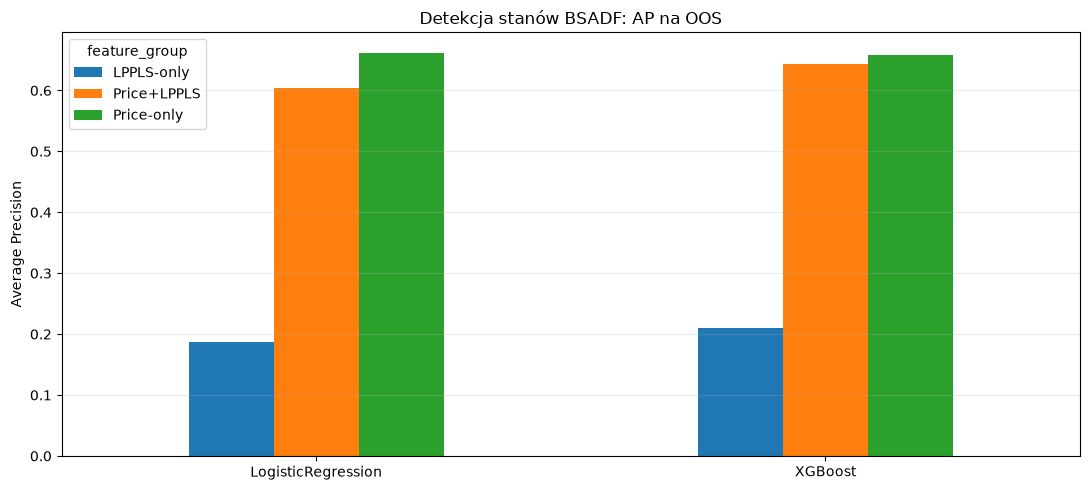

In [6]:
fig,ax=plt.subplots(figsize=(11,5))
heat=summary.loc[summary.model.isin(MODELS)].pivot(index='model',columns='feature_group',values='AP')
heat.plot.bar(ax=ax,rot=0)
ax.set(title='Detekcja stanów BSADF: AP na OOS',ylabel='Average Precision',xlabel='')
ax.grid(axis='y',alpha=.25)
fig.tight_layout();fig.savefig(OUT/'14_01_AP_OOS.png',dpi=170);plt.show()

## 5. Zamrożony model BTC do walidacji międzyrynkowej (notatnik 16)
Trening do 2019, wybór progu z 2020; NIE dopasowujemy go do innego rynku.
Model służy do transferu, nie jest modelem dobranym po wynikach 2021–24.

In [7]:
transfer_train=data[data.date.dt.year<=2019]
transfer_val=data[data.date.dt.year==2020]
if transfer_train.y.nunique()==2 and not transfer_val.empty:
    cols=groups['Price+LPPLS']
    params,_=choose_hyperparams('XGBoost',cols,transfer_train)
    transfer_model=make_estimator('XGBoost',params)
    transfer_model.fit(transfer_train[cols],transfer_train.y)
    tscore=transfer_model.predict_proba(transfer_val[cols])[:,1]
    tthreshold,tstatus,_=choose_threshold(transfer_val.y,tscore)
    bundle={'model':transfer_model,'feature_cols':cols,'threshold':float(tthreshold),
            'threshold_status':tstatus,'model_name':'XGBoost',
            'feature_group':'Price+LPPLS','train_end':'2019-12-31',
            'calibration_year':2020,'label':'BSADF_sampled_asof_state'}
    joblib.dump(bundle,OUT/'14_transfer_BTC_XGB_PriceLPPLS.joblib')
    print('Zapisano model transferowy. Threshold:',tthreshold,'status:',tstatus)
else:
    print('Brak obu klas w treningu 2015–2019 albo brakuje 2020. Transfer nie został zapisany.')

print('Wyniki:',OUT.resolve())

Zapisano model transferowy. Threshold: 0.2 status: validated_budget
Wyniki: C:\Users\cynar\Desktop\projects\article\14_wyniki_bubble
